# **01 |** Área de estudio: provincia de Cusco

> **Objetivo:** cargar el límite provincial descargado de GeoPerú, verificar su geometría y sistema de coordenadas, calcular su superficie, visualizarlo y generar un Asset reutilizable en Google Earth Engine (GEE).
> 
> **Área de estudio:** provincia de Cusco, departamento de Cusco (códigos UBIGEO: `0801`).
> 
> **Insumo:** archivo GeoJSON descargado del visor GeoPerú. La institución productora, fecha de descarga, versión y URL exacta deben registrarse a partir de la ficha o metadatos de la descarga; no se infieren del nombre del archivo.
> 
> **Salidas:**
> - ``data/processed/cusco_aoi.geojson``
> - Asset GEE: `projects/cusco-land-cover/assets/cusco_aoi`

El GeoJSON original se conserva sin modificaciones. La geometría exportada se simplifica a 10 metros para reducir su complejidad, manteniendo la topología.

## 1. Configuración

La ruta del GeoJSON y los datos de procedencia se registran en esta sección. La exportación a GEE está desactivada por defecto y se ejecuta únicamente cuando se habilita explícitamente.

In [1]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt

# Cargar el límite provincial de Cusco.
PROJECT_ROOT = Path.cwd() / ".."

GEOJSON_PATH = (
    PROJECT_ROOT / "data" / "raw" / "prov" / "Limite_Provincial_CUSCO.geojson"
)

GEOJSON_OUTPUT = (
    PROJECT_ROOT / "data" / "processed" / "prov" / "cusco-aoi.geojson"
)

## 2. Lectura e inspección del GeoJSON

Se revisan:
1. El sistema de referencia,
2. los registros, los atributos y 
3. los tipos de geometría. 

> El archivo debe incluir un CRS definido y geometrías poligonales.

In [2]:
aoi = gpd.read_file(GEOJSON_PATH)

# Validación básica del archivo de origen
if aoi.empty:
    raise ValueError("El GeoJSON no contiene entidades.")

if aoi.crs is None:
    raise ValueError("El GeoJSON no declara un CRS. Verifica sus metadatos.")

# Resumen general del dataset completo
print(f"Total de registros cargados: {len(aoi)}")
print(f"Sistema de coordenadas (CRS): {aoi.crs}")
print(f"Columnas disponibles: {list(aoi.columns)}")

display(aoi.drop(columns=aoi.geometry.name).head())


Total de registros cargados: 1
Sistema de coordenadas (CRS): EPSG:4326
Columnas disponibles: ['id', 'idprov', 'nombprov', 'nombdep', 'geometry']


,id,idprov,nombprov,nombdep
0,peru_provincia_.fid-50926f97_1a1e2262238_-683e,0801,CUSCO,CUSCO


## 3. Selección de la provincia

El archivo contiene una sola entidad, se utiliza como límite provincial.

In [3]:
# provincia_aoi = aoi[aoi["idprov"] == "0801"].copy()
provincia_aoi = aoi.copy()

if len(provincia_aoi) != 1:
    raise ValueError(f"Se esperaba 1 entidad para Cusco, pero se encontraron {len(provincia_aoi)}.")

geom = provincia_aoi.geometry.iloc[0]

# Validaciones geométricas exclusivas del área de estudio
if geom is None or geom.is_empty:
    raise ValueError("La geometría de la provincia de Cusco está vacía.")

if not geom.is_valid:
    raise ValueError("La geometría no es válida. Corrige el archivo de origen antes de continuar.")

if geom.geom_type not in ("Polygon", "MultiPolygon"):
    raise TypeError(f"Se esperaba un polígono, pero se obtuvo: {geom.geom_type}")

# Confirmación del AOI listo para análisis
print("AOI validado: Provincia de Cusco (UBIGEO 0801)")
print(f"Tipo de geometría: {geom.geom_type} | Válida: {geom.is_valid}")


AOI validado: Provincia de Cusco (UBIGEO 0801)
Tipo de geometría: MultiPolygon | Válida: True


## 4. Sistema de coordenadas y superficie

El GeoJSON se transforma a EPSG:6933, una proyección global equivalente adecuada para calcular superficies. La superficie se expresa en kilómetros cuadrados. Para su uso en GEE, la geometría se transforma posteriormente a EPSG:4326.

In [4]:
AREA_CRS = "EPSG:6933"

provincia_area = provincia_aoi.to_crs(AREA_CRS)
area_km2 = provincia_area.geometry.area.iloc[0] / 1_000_000

print(f"Superficie aproximada: {area_km2:,.2f} km²")
print("CRS de cálculo de área:", AREA_CRS)
print("CRS original:", aoi.crs)


Superficie aproximada: 529.18 km²
CRS de cálculo de área: EPSG:6933
CRS original: EPSG:4326


## 5. Visualización del área de estudio

La representación permite comprobar que el límite corresponde a la provincia seleccionada.

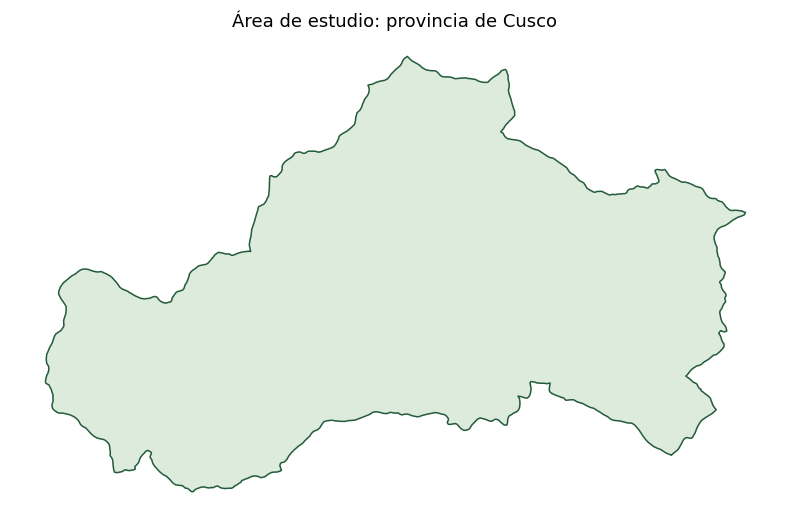

In [5]:
fig, ax = plt.subplots(figsize=(8, 8))

provincia_aoi.plot(
    ax=ax,
    facecolor="#dcebdc",
    edgecolor="#245b3c",
    linewidth=1.1
)

ax.set_title("Área de estudio: provincia de Cusco", fontsize=13)
ax.set_axis_off()
plt.tight_layout()
plt.show()


## 6. Preparación de la geometría de salida

Se conserva la geometría provincial sin simplificación. La transformación a EPSG:4326 prepara las coordenadas para el GeoJSON y su conversión a geometría de Earth Engine.

In [6]:
# Se conserva la geometría original y se transforma a coordenadas geográficas.
aoi_aoi = provincia_aoi.to_crs("EPSG:4326").copy()

geom_salida = aoi_aoi.geometry.iloc[0]
if geom_salida.is_empty or not geom_salida.is_valid:
    raise ValueError("La geometría de salida no es válida.")

print(f"Superficie conservada: {area_km2:,.2f} km²")
print("CRS de salida:", aoi_aoi.crs)

Superficie conservada: 529.18 km²
CRS de salida: EPSG:4326


## 7. Exportación del GeoJSON

Se guarda una copia procesada del límite provincial en `data/processed/prov/`. El archivo descargado de GeoPerú permanece intacto.

In [7]:
# Preparar la geometría de salida en coordenadas geográficas.
provincia_salida = provincia_aoi.to_crs("EPSG:4326").copy()

# Conservar únicamente la geometría y el área calculada.
provincia_salida = provincia_salida[["geometry"]].copy()
provincia_salida["area_km2"] = round(area_km2, 4)

# Crear carpeta de destino y exportar.
GEOJSON_OUTPUT.parent.mkdir(parents=True, exist_ok=True)

provincia_salida.to_file(
    GEOJSON_OUTPUT,
    driver="GeoJSON"
)

print(f"GeoJSON exportado: {GEOJSON_OUTPUT}")
print("CRS de salida:", provincia_salida.crs)

GeoJSON exportado: d:\workspace\projects\project-collab\cusco-land-cover-analysis\notebooks\..\data\processed\prov\cusco-aoi.geojson
CRS de salida: EPSG:4326


## 8. Exportación a Google Earth Engine

El Asset permite que los notebooks de procesamiento satelital reutilicen una única delimitación. La exportación se ejecuta solo cuando `EXPORTAR_A_GEE = True`.

Si el Asset ya existe, el proceso se detiene para evitar sobrescribirlo accidentalmente. La tarea debe completarse en Earth Engine antes de utilizar el Asset en otros notebooks.

In [8]:
GEE_PROJECT = "cusco-land-cover"
ASSET_ID = f"projects/{GEE_PROJECT}/assets/cusco_01_aoi"
EXPORTAR_A_GEE = True

> Previo al siguiente código creamos la carpeta ``assets/`` en el proyecto ``GEE_PROJECT`` en el ``Earth Engine Code Editor``

In [11]:
if EXPORTAR_A_GEE:
    import ee
    import json

    # Inicializar Google Earth Engine.
    try:
        ee.Initialize(project=GEE_PROJECT)
    except Exception:
        ee.Authenticate()
        ee.Initialize(project=GEE_PROJECT)

    # Comprobar si el Asset ya existe.
    try:
        ee.data.getAsset(ASSET_ID)
        asset_existe = True
    except Exception as error:
        mensaje = str(error).lower()

        if any(texto in mensaje for texto in ["not found", "does not exist", "404"]):
            asset_existe = False
        else:
            raise

    if asset_existe:
        print("El Asset ya existe. No se realizará otra exportación.")
        print("Asset:", ASSET_ID)

    else:
        # Obtener la geometría de la provincia en EPSG:4326.
        provincia_salida = provincia_aoi.to_crs("EPSG:4326").copy()

        geojson_geom = json.loads(
            provincia_salida.to_json()
        )["features"][0]["geometry"]

        ee_geom = ee.Geometry(geojson_geom)

        # Recuperar los atributos del GeoJSON original.
        registro = provincia_aoi.iloc[0]

        propiedades = {
            "idprov": str(registro["idprov"]),
            "provincia": str(registro["nombprov"]),
            "departamento": str(registro["nombdep"]),
            "area_km2": float(round(area_km2, 4))
        }

        # Crear la colección y exportarla como Asset.
        coleccion = ee.FeatureCollection([
            ee.Feature(ee_geom, propiedades)
        ])

        tarea = ee.batch.Export.table.toAsset(
            collection=coleccion,
            description="cusco_01_aoi",
            assetId=ASSET_ID
        )

        tarea.start()

        print("Exportación iniciada.")
        print("ID de tarea:", tarea.id)
        print("Asset destino:", ASSET_ID)
        print("Estado inicial:", tarea.status().get("state"))

else:
    print("Exportación a GEE desactivada.")
    print("Asset previsto:", ASSET_ID)
    print("Para exportar, cambia EXPORTAR_A_GEE a True.")

Exportación iniciada.
ID de tarea: EQEXR7KLH2IKPZWMEISSZHN7
Asset destino: projects/cusco-land-cover/assets/cusco_01_aoi
Estado inicial: READY


> Comprobamos si efectivamente cargó el ``GEE aoi``

In [12]:
import ee

ee.Initialize(project="cusco-land-cover")

ASSET_ID = "projects/cusco-land-cover/assets/cusco_01_aoi"

try:
    asset = ee.data.getAsset(ASSET_ID)
    print("Asset encontrado:", asset["name"])
    print("Tipo:", asset["type"])
except Exception as error:
    print("No se encontró el Asset.")
    print(error)

Asset encontrado: projects/cusco-land-cover/assets/cusco_01_aoi
Tipo: TABLE
